# Notebook 01 — Exploratory Data Analysis (EDA) & Data Cleaning

**Project:** Credit Default Risk Prediction on 30,000 Customer Records (UCI Taiwan Credit Card Default Dataset, 2005)  
**Input:** `data/raw/default_of_credit_card_clients.xls`  
**Output:** `data/processed/clean.csv`

---

### Objectives
1. **Load & Inspect** the 30,000 customer records (`header=1`), standardizing column names (`default payment next month` $\rightarrow$ `default`, `PAY_0` $\rightarrow$ `PAY_1` so month indices run consistently from `1` = September 2005 to `6` = April 2005).
2. **Audit Data Quality:** Check missing values, duplicate `ID`s, duplicate feature rows, negative billing balances, and undocumented category codes in `EDUCATION`, `MARRIAGE`, and `PAY_1..PAY_6`.
3. **Apply & Document Cleaning Decisions:** Consolidate undocumented `EDUCATION` (`{0, 5, 6}` $\rightarrow$ `4`) and `MARRIAGE` (`0` $\rightarrow$ `3`) codes, preserve negative bill statements (overpayments/credits) and `-2/-1/0` repayment statuses, and drop the non-predictive `ID` column.
4. **Analyze Target & Feature Distributions:** Quantify class imbalance (`22.12%` default rate) and examine univariate, bivariate, and correlation patterns across credit limits, repayment history, and billing statements.

## 1. Load Raw Dataset & Standardize Column Names

Row 0 of `default_of_credit_card_clients.xls` contains generic codes (`X1..X23`, `Y`), while Row 1 holds the true column headers. We load with `header=1`, rename the target column `default payment next month` to `default`, and rename `PAY_0` to `PAY_1` so that all temporal series (`PAY_1..6`, `BILL_AMT1..6`, `PAY_AMT1..6`) share the same month index (`1 = Sept 2005` through `6 = April 2005`).

In [5]:
from pathlib import Path
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


In [8]:
df_raw = pd.read_excel("data/raw/default_of_credit_card_clients.xls", header=1)

df = df_raw.rename(columns={
    "default payment next month": "default",
    "PAY_0": "PAY_1",
})

print(f"Dataset shape: {df.shape[0]:,} rows x {df.shape[1]} columns")
print("\nColumn data types:")
print(df.dtypes.to_frame(name="dtype").T)
df.head()

C:\Users\piyus\AppData\Local\Temp\ipykernel_1448\2053936051.py:1: Pandas4Warning: The xlrd engine is deprecated and will be removed in a future version. Use the calamine engine instead, by setting engine='calamine'.
  df_raw = pd.read_excel("data/raw/default_of_credit_card_clients.xls", header=1)


Dataset shape: 30,000 rows x 25 columns

Column data types:
          ID LIMIT_BAL    SEX EDUCATION MARRIAGE    AGE  PAY_1  PAY_2  PAY_3  \
dtype  int64     int64  int64     int64    int64  int64  int64  int64  int64   

       PAY_4  ... BILL_AMT4 BILL_AMT5 BILL_AMT6 PAY_AMT1 PAY_AMT2 PAY_AMT3  \
dtype  int64  ...     int64     int64     int64    int64    int64    int64   

      PAY_AMT4 PAY_AMT5 PAY_AMT6 default  
dtype    int64    int64    int64   int64  

[1 rows x 25 columns]


,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_1,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default
0,1,20000,2,2,1,24,2,2,-1,-1,...,0,0,0,0,689,0,0,0,0,1
1,2,120000,2,2,2,26,-1,2,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,3,90000,2,2,2,34,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,4,50000,2,2,1,37,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,5,50000,1,2,1,57,-1,0,-1,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0


In [12]:
# Summary statistics for all 25 columns
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
ID,30000.0,15000.50,8660.40,1.0,7500.75,15000.5,22500.25,30000.0
LIMIT_BAL,30000.0,167484.32,129747.66,10000.0,50000.00,140000.0,240000.00,1000000.0
SEX,30000.0,1.60,0.49,1.0,1.00,2.0,2.00,2.0
EDUCATION,30000.0,1.85,0.79,0.0,1.00,2.0,2.00,6.0
MARRIAGE,30000.0,1.55,0.52,0.0,1.00,2.0,2.00,3.0
AGE,30000.0,35.49,9.22,21.0,28.00,34.0,41.00,79.0
PAY_1,30000.0,-0.02,1.12,-2.0,-1.00,0.0,0.00,8.0
PAY_2,30000.0,-0.13,1.20,-2.0,-1.00,0.0,0.00,8.0
PAY_3,30000.0,-0.17,1.20,-2.0,-1.00,0.0,0.00,8.0
PAY_4,30000.0,-0.22,1.17,-2.0,-1.00,0.0,0.00,8.0


## 2. Data Quality & Anomaly Checks

We inspect:
- **Missing values** across all 25 columns.
- **Duplicate checks** (with and without `ID`).
- **Categorical distributions** for `SEX`, `EDUCATION`, `MARRIAGE`, and `PAY_1..PAY_6` to spot undocumented codes.
- **Negative billing statement values** (`BILL_AMT1..6 < 0`), which represent customer credit balances / overpayments.

In [11]:
print("Total missing values:", df.isnull().sum().sum())
print("Duplicate full rows (including ID):", df.duplicated().sum())
print("Duplicate customer IDs:", df["ID"].duplicated().sum())
print("Identical feature profiles (excluding ID):", df.drop(columns=["ID"]).duplicated().sum())

print("\n--- Categorical Value Counts (Before Cleaning) ---")
for col in ["SEX", "EDUCATION", "MARRIAGE"]:
    print(f"\n{col}:")
    vc = df[col].value_counts().sort_index()
    pct = (df[col].value_counts(normalize=True).sort_index() * 100).round(2)
    print(pd.DataFrame({"count": vc, "pct (%)": pct}))

Total missing values: 0
Duplicate full rows (including ID): 0
Duplicate customer IDs: 0
Identical feature profiles (excluding ID): 35

--- Categorical Value Counts (Before Cleaning) ---

SEX:
     count  pct (%)
SEX                
1    11888    39.63
2    18112    60.37

EDUCATION:
           count  pct (%)
EDUCATION                
0             14     0.05
1          10585    35.28
2          14030    46.77
3           4917    16.39
4            123     0.41
5            280     0.93
6             51     0.17

MARRIAGE:
          count  pct (%)
MARRIAGE                
0            54     0.18
1         13659    45.53
2         15964    53.21
3           323     1.08


In [13]:
# Inspect repayment status distributions across all 6 months (PAY_1 = Sept 2005 ... PAY_6 = April 2005)
pay_cols = [f"PAY_{i}" for i in range(1, 7)]
pay_dist = pd.DataFrame({col: df[col].value_counts() for col in pay_cols}).fillna(0).astype(int)
pay_dist.index.name = "Repayment Status Code"
print("Repayment status counts across PAY_1..PAY_6:")
pay_dist

Repayment status counts across PAY_1..PAY_6:


,PAY_1,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6
Repayment Status Code,,,,,,
-2,2759,3782,4085,4348,4546,4895
-1,5686,6050,5938,5687,5539,5740
0,14737,15730,15764,16455,16947,16286
1,3688,28,4,2,0,0
2,2667,3927,3819,3159,2626,2766
3,322,326,240,180,178,184
4,76,99,76,69,84,49
5,26,25,21,35,17,13
6,11,12,23,5,4,19


In [6]:
# Check negative values in BILL_AMT1..6 and PAY_AMT1..6
bill_cols = [f"BILL_AMT{i}" for i in range(1, 7)]
pay_amt_cols = [f"PAY_AMT{i}" for i in range(1, 7)]

neg_summary = pd.DataFrame({
    "Negative Count (BILL_AMT)": [(df[c] < 0).sum() for c in bill_cols],
    "Min Value (BILL_AMT)": [df[c].min() for c in bill_cols],
    "Zero Count (BILL_AMT)": [(df[c] == 0).sum() for c in bill_cols],
    "Negative Count (PAY_AMT)": [(df[c] < 0).sum() for c in pay_amt_cols],
    "Zero Count (PAY_AMT)": [(df[c] == 0).sum() for c in pay_amt_cols],
}, index=[f"Month {i}" for i in range(1, 7)])
neg_summary

,Negative Count (BILL_AMT),Min Value (BILL_AMT),Zero Count (BILL_AMT),Negative Count (PAY_AMT),Zero Count (PAY_AMT)
Month 1,590,-165580,2008,0,5249
Month 2,669,-69777,2506,0,5396
Month 3,655,-157264,2870,0,5968
Month 4,675,-170000,3195,0,6408
Month 5,655,-81334,3506,0,6703
Month 6,688,-339603,4020,0,7173


## 3. Data Cleaning Decisions

Based on our audit and the official UCI dataset documentation, we apply the following explicit cleaning rules:

1. **`EDUCATION` undocumented codes (`{0, 5, 6}` $\rightarrow$ `4`):**  
   The official dictionary defines `1 = Graduate School`, `2 = University`, `3 = High School`, `4 = Others`. The raw file also contains `0` (14 rows), `5` (280 rows), and `6` (51 rows). We merge `{0, 5, 6}` into category `4` (`Others`), raising category `4` from 123 to 468 rows.
2. **`MARRIAGE` undocumented code (`0` $\rightarrow$ `3`):**  
   The official dictionary defines `1 = Married`, `2 = Single`, `3 = Others`. The raw file contains `0` (54 rows), which we merge into `3` (`Others`), raising category `3` from 323 to 377 rows.
3. **Repayment status scale (`PAY_1..PAY_6`):**  
   In addition to documented values (`-1 = paid duly`, `1..8 = months of payment delay`), the file contains `-2` and `0` (and no `9`s). Following standard domain interpretation for this dataset, we treat **`-2` = no credit consumption**, **`-1` = paid balance in full**, **`0` = revolving credit (paid minimum due only, no delay)**, and **`>= 1` = number of months payment is past due**. Consequently, values `<= 0` indicate **not delayed**. We retain the exact integer codes (`-2` to `8`) because they carry strong predictive signal.
4. **Negative `BILL_AMT` values:**  
   Between 590 and 688 records per month have negative bill statements (down to `-339,603` NT$). These represent valid credit balances resulting from overpayments or refunds, so we retain them without dropping or Winsorizing.
5. **Drop `ID` and retain all 30,000 customer rows:**  
   `ID` is a sequential row identifier (`1..30,000`) with zero predictive meaning and is dropped. All 30,000 rows represent distinct customer IDs (the 35 duplicate feature vectors are mostly inactive accounts with zero bills and zero payments across all 6 months), so we retain all 30,000 records.

In [16]:
df_clean = df.copy()

# 1. Merge undocumented EDUCATION codes {0, 5, 6} -> 4 (Others)
df_clean["EDUCATION"] = df_clean["EDUCATION"].replace({0: 4, 5: 4, 6: 4})

# 2. Merge undocumented MARRIAGE code 0 -> 3 (Others)
df_clean["MARRIAGE"] = df_clean["MARRIAGE"].replace({0: 3})

# 3. Drop non-predictive ID column
df_clean = df_clean.drop(columns=["ID"])

assert df_clean.shape == (30000, 24), f"Unexpected shape: {df_clean.shape}"
assert set(df_clean["EDUCATION"].unique()) == {1, 2, 3, 4}
assert set(df_clean["MARRIAGE"].unique()) == {1, 2, 3}

print("Cleaned EDUCATION counts:\n", df_clean["EDUCATION"].value_counts().sort_index())
print("\nCleaned MARRIAGE counts:\n", df_clean["MARRIAGE"].value_counts().sort_index())

Cleaned EDUCATION counts:
 EDUCATION
1    10585
2    14030
3     4917
4      468
Name: count, dtype: int64

Cleaned MARRIAGE counts:
 MARRIAGE
1    13659
2    15964
3      377
Name: count, dtype: int64


## 4. Target Variable Analysis (`default`)

The target variable `default` (`1 = default next month`, `0 = non-default`) is moderately imbalanced:
- **Non-default (`0`):** `23,364` customers (`77.88%`)
- **Default (`1`):** `6,636` customers (`22.12%`)

**Modeling Implications:**
- A naive majority-class classifier achieves `77.88%` accuracy while catching `0%` of defaults.
- We must use a **stratified train-test split** (`stratify=y`) and `StratifiedKFold` cross-validation.
- We must evaluate models using **PR-AUC (Average Precision)**, **ROC-AUC**, **F1-score**, **Precision**, and **Recall**, and apply **class weighting** (`class_weight="balanced"` / `scale_pos_weight`) plus **validation threshold tuning**.

Total Customers: 30000
Non-Default Customers: 23364
Default Customers: 6636


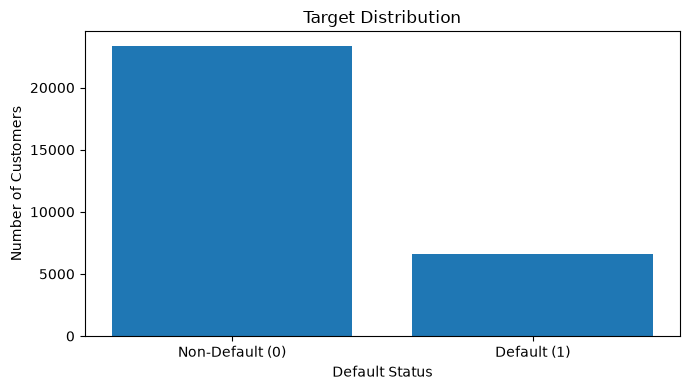

In [18]:
target_counts = df_clean["default"].value_counts().sort_index()

print("Total Customers:", len(df_clean))
print("Non-Default Customers:", target_counts[0])
print("Default Customers:", target_counts[1])

plt.figure(figsize=(7, 4))
plt.bar(["Non-Default (0)", "Default (1)"], target_counts.values)

plt.xlabel("Default Status")
plt.ylabel("Number of Customers")
plt.title("Target Distribution")
plt.tight_layout()
plt.show()

## 5. Univariate Analysis

We inspect the distributions of continuous financial/demographic variables (`LIMIT_BAL`, `AGE`, `BILL_AMT1..6`, `PAY_AMT1..6`) and cleaned categorical variables (`SEX`, `EDUCATION`, `MARRIAGE`, `PAY_1`).
- Financial amounts (`LIMIT_BAL`, `BILL_AMT*`, `PAY_AMT*`) exhibit pronounced **right skewness** and extreme upper tails, motivating `log1p` transformations in Feature Engineering (`02_feature_engineering.ipynb`).

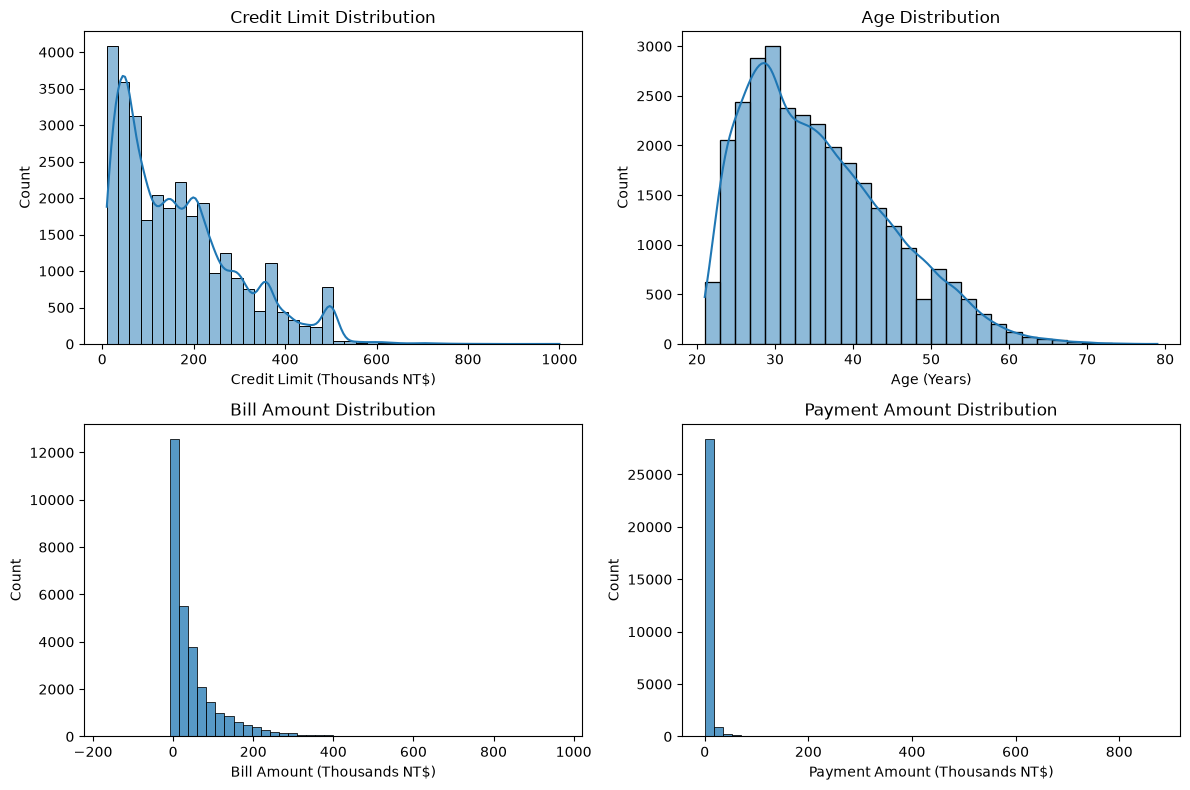

In [23]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

sns.histplot(df_clean["LIMIT_BAL"] / 1000, bins=40, kde=True, ax=axes[0, 0])
axes[0, 0].set_title("Credit Limit Distribution")
axes[0, 0].set_xlabel("Credit Limit (Thousands NT$)")

sns.histplot(df_clean["AGE"], bins=30, kde=True, ax=axes[0, 1])
axes[0, 1].set_title("Age Distribution")
axes[0, 1].set_xlabel("Age (Years)")

sns.histplot(df_clean["BILL_AMT1"] / 1000, bins=50, ax=axes[1, 0])
axes[1, 0].set_title("Bill Amount Distribution")
axes[1, 0].set_xlabel("Bill Amount (Thousands NT$)")

sns.histplot(df_clean["PAY_AMT1"] / 1000, bins=50, ax=axes[1, 1])
axes[1, 1].set_title("Payment Amount Distribution")
axes[1, 1].set_xlabel("Payment Amount (Thousands NT$)")

plt.tight_layout()
plt.show()

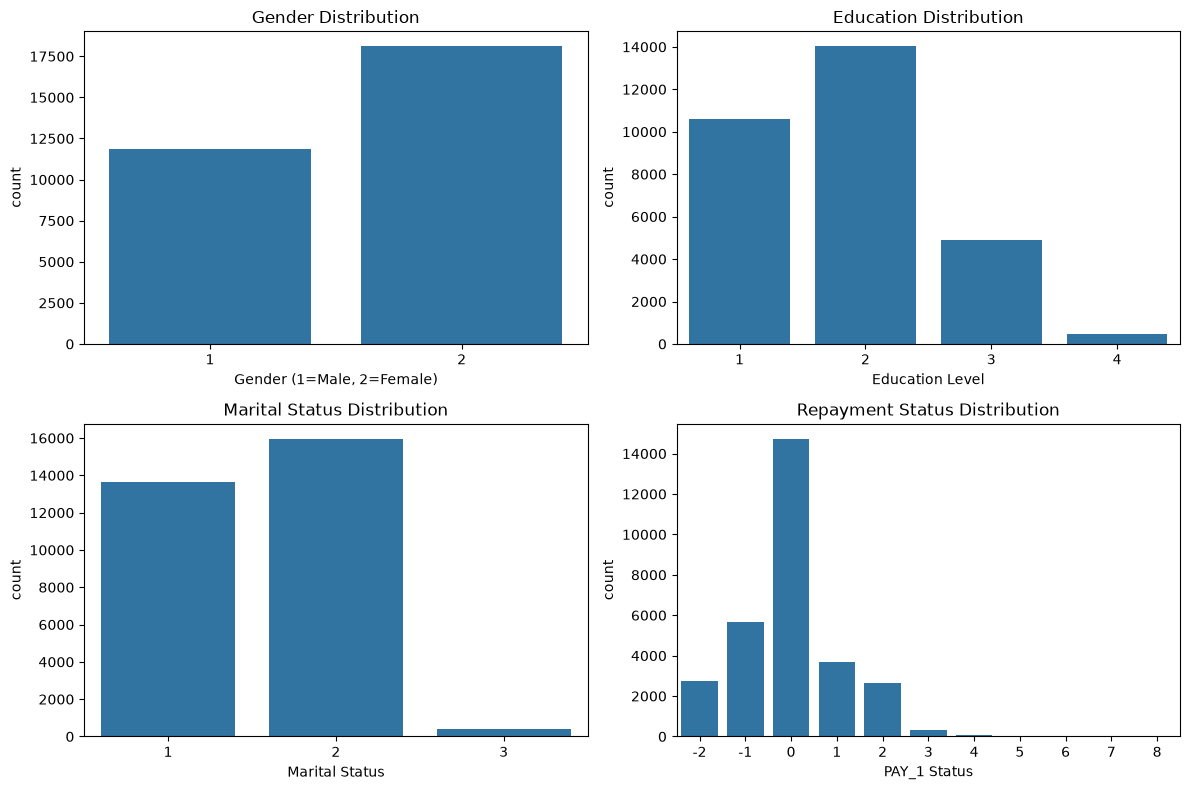

In [24]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

sns.countplot(x=df_clean["SEX"], ax=axes[0, 0])
axes[0, 0].set_title("Gender Distribution")
axes[0, 0].set_xlabel("Gender (1=Male, 2=Female)")

sns.countplot(x=df_clean["EDUCATION"], ax=axes[0, 1])
axes[0, 1].set_title("Education Distribution")
axes[0, 1].set_xlabel("Education Level")

sns.countplot(x=df_clean["MARRIAGE"], ax=axes[1, 0])
axes[1, 0].set_title("Marital Status Distribution")
axes[1, 0].set_xlabel("Marital Status")

sns.countplot(x=df_clean["PAY_1"], ax=axes[1, 1])
axes[1, 1].set_title("Repayment Status Distribution")
axes[1, 1].set_xlabel("PAY_1 Status")

plt.tight_layout()
plt.show()

## 6. Bivariate Analysis vs. Default

We next examine how default rate (`mean(default)`) varies across:
1. **Demographics & Credit Limit Deciles:** `SEX`, `EDUCATION`, `MARRIAGE`, age buckets, and `LIMIT_BAL` deciles.
2. **Repayment History (`PAY_1..PAY_6`):** Default probability by repayment status code.
3. **Continuous Financial Distributions Split by Default:** Box/violin comparisons of `LIMIT_BAL`, `BILL_AMT1`, and `PAY_AMT1`.

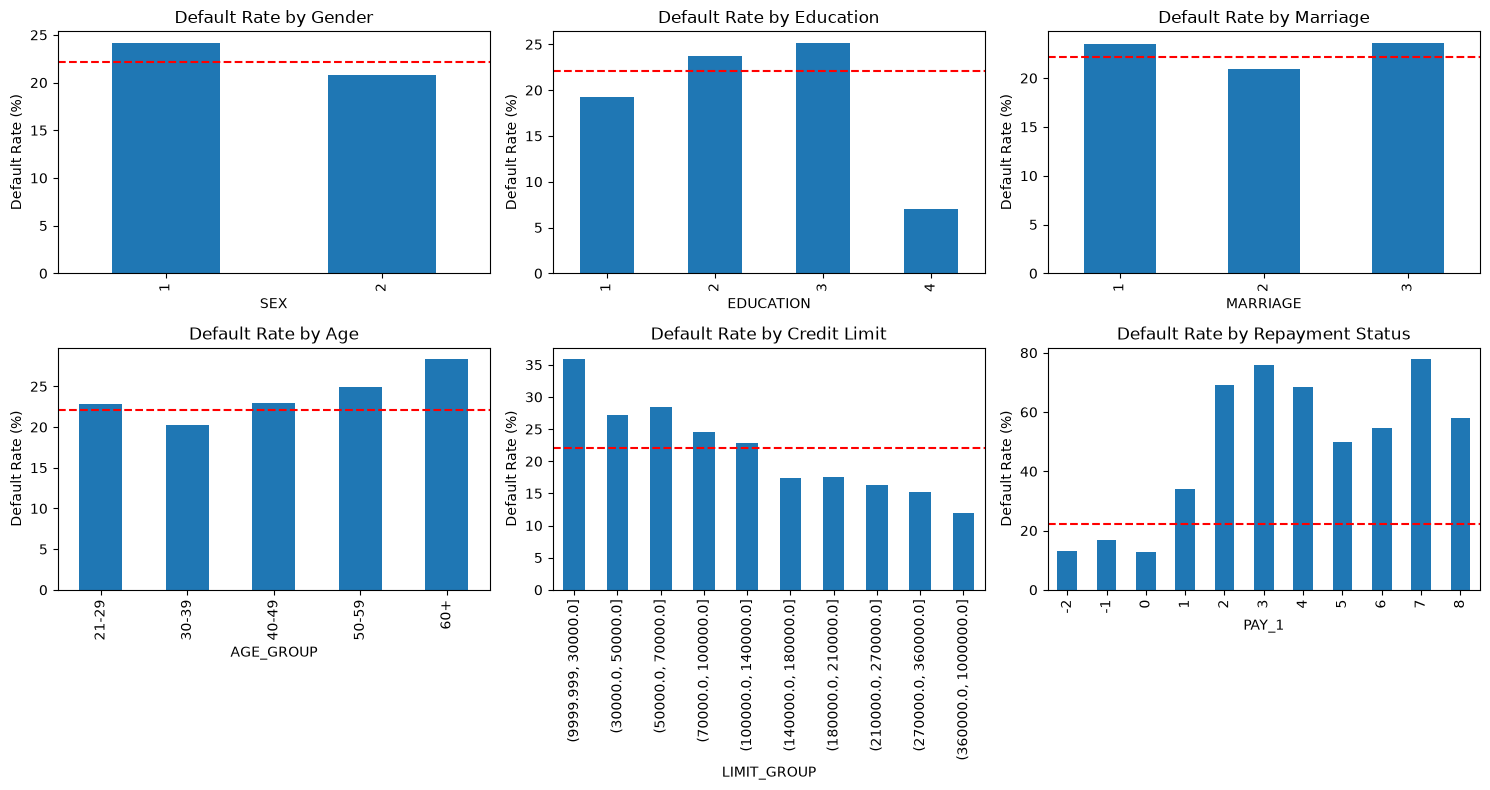

Default Rate by PAY_1:
PAY_1
-2    13.23
-1    16.78
 0    12.81
 1    33.95
 2    69.14
 3    75.78
 4    68.42
 5    50.00
 6    54.55
 7    77.78
 8    57.89
Name: default, dtype: float64

Overall Default Rate: 22.12 %


In [25]:
# Create age groups and credit limit groups
df_biv = df_clean.copy()

df_biv["AGE_GROUP"] = pd.cut(
    df_biv["AGE"],
    bins=[20, 29, 39, 49, 59, 80],
    labels=["21-29", "30-39", "40-49", "50-59", "60+"]
)

df_biv["LIMIT_GROUP"] = pd.qcut(df_biv["LIMIT_BAL"], q=10, duplicates="drop")

# Overall default rate
overall_rate = df_clean["default"].mean() * 100

# Create subplots
fig, axes = plt.subplots(2, 3, figsize=(15, 8))

# 1. Default by Gender
(df_biv.groupby("SEX")["default"].mean() * 100).plot(kind="bar", ax=axes[0, 0])
axes[0, 0].set_title("Default Rate by Gender")

# 2. Default by Education
(df_biv.groupby("EDUCATION")["default"].mean() * 100).plot(kind="bar", ax=axes[0, 1])
axes[0, 1].set_title("Default Rate by Education")

# 3. Default by Marriage
(df_biv.groupby("MARRIAGE")["default"].mean() * 100).plot(kind="bar", ax=axes[0, 2])
axes[0, 2].set_title("Default Rate by Marriage")

# 4. Default by Age
(df_biv.groupby("AGE_GROUP", observed=False)["default"].mean() * 100).plot(kind="bar", ax=axes[1, 0])
axes[1, 0].set_title("Default Rate by Age")

# 5. Default by Credit Limit
(df_biv.groupby("LIMIT_GROUP", observed=False)["default"].mean() * 100).plot(kind="bar", ax=axes[1, 1])
axes[1, 1].set_title("Default Rate by Credit Limit")

# 6. Default by Repayment Status
(df_biv.groupby("PAY_1")["default"].mean() * 100).plot(kind="bar", ax=axes[1, 2])
axes[1, 2].set_title("Default Rate by Repayment Status")

# Add overall default rate reference line
for ax in axes.flat:
    ax.axhline(overall_rate, color="red", linestyle="--")
    ax.set_ylabel("Default Rate (%)")

plt.tight_layout()
plt.show()

# Print default rate by repayment status
print("Default Rate by PAY_1:")
print((df_clean.groupby("PAY_1")["default"].mean() * 100).round(2))

# Print total default rate
print("\nOverall Default Rate:", round(overall_rate, 2), "%")

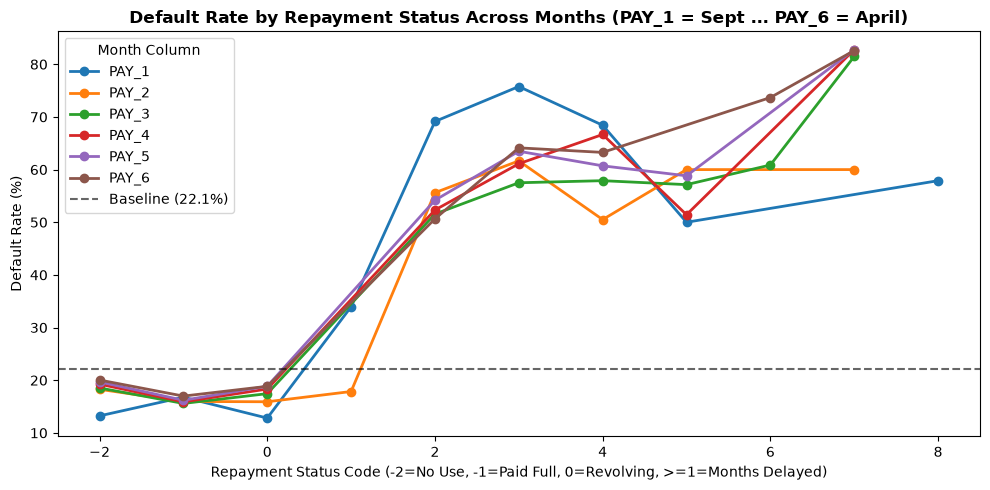

In [28]:
# Default rate trajectory across all 6 repayment status columns (PAY_1..PAY_6)
fig, ax = plt.subplots(figsize=(10, 5))
for col in pay_cols:
    rates = df_clean.groupby(col)["default"].agg(["count", "mean"])
    # Plot statuses with >= 15 observations for stable rate curves
    valid = rates[rates["count"] >= 15]
    ax.plot(valid.index, valid["mean"] * 100, marker="o", linewidth=2, label=col)

ax.axhline(overall_rate, color="black", linestyle="--", alpha=0.6, label=f"Baseline ({overall_rate:.1f}%)")
ax.set_xlabel("Repayment Status Code (-2=No Use, -1=Paid Full, 0=Revolving, >=1=Months Delayed)")
ax.set_ylabel("Default Rate (%)")
ax.set_title("Default Rate by Repayment Status Across Months (PAY_1 = Sept ... PAY_6 = April)", fontweight="bold")
ax.legend(title="Month Column")
plt.tight_layout()
plt.show()

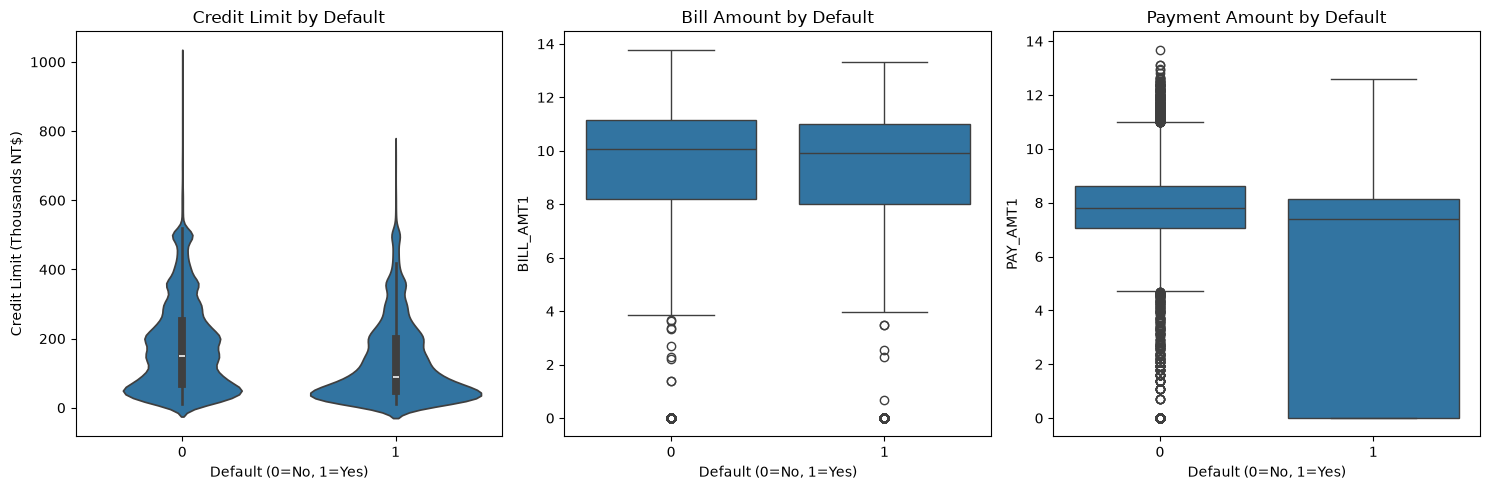

In [31]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# Credit Limit
sns.violinplot(x="default", y=df_clean["LIMIT_BAL"] / 1000, data=df_clean, ax=axes[0])
axes[0].set_title("Credit Limit by Default")
axes[0].set_xlabel("Default (0=No, 1=Yes)")
axes[0].set_ylabel("Credit Limit (Thousands NT$)")

# Bill Amount
sns.boxplot(x="default", y=np.log1p(df_clean["BILL_AMT1"].clip(lower=0)), data=df_clean, ax=axes[1])
axes[1].set_title("Bill Amount by Default")
axes[1].set_xlabel("Default (0=No, 1=Yes)")

# Payment Amount
sns.boxplot(x="default", y=np.log1p(df_clean["PAY_AMT1"]), data=df_clean, ax=axes[2])
axes[2].set_title("Payment Amount by Default")
axes[2].set_xlabel("Default (0=No, 1=Yes)")

plt.tight_layout()
plt.show()

## 7. Correlation & Multicollinearity Analysis

We compute the Pearson correlation matrix across all 24 cleaned columns:
- **`BILL_AMT1..BILL_AMT6` are heavily collinear** ($r = 0.80$ to $0.95$ between adjacent months), because revolving balances carry over month-to-month.
- **`PAY_1..PAY_6` show strong positive serial correlation** ($r = 0.47$ to $0.82$), reflecting persistent delinquency streaks.
- **With `default`:** `PAY_1` ($r = 0.325$), `PAY_2` ($r = 0.264$), `PAY_3` ($r = 0.235$), `PAY_4` ($r = 0.217$), `PAY_5` ($r = 0.204$), and `PAY_6` ($r = 0.187$) have the strongest positive linear correlations, while `LIMIT_BAL` ($r = -0.154$) and `PAY_AMT1` ($r = -0.073$) are negatively correlated with default.

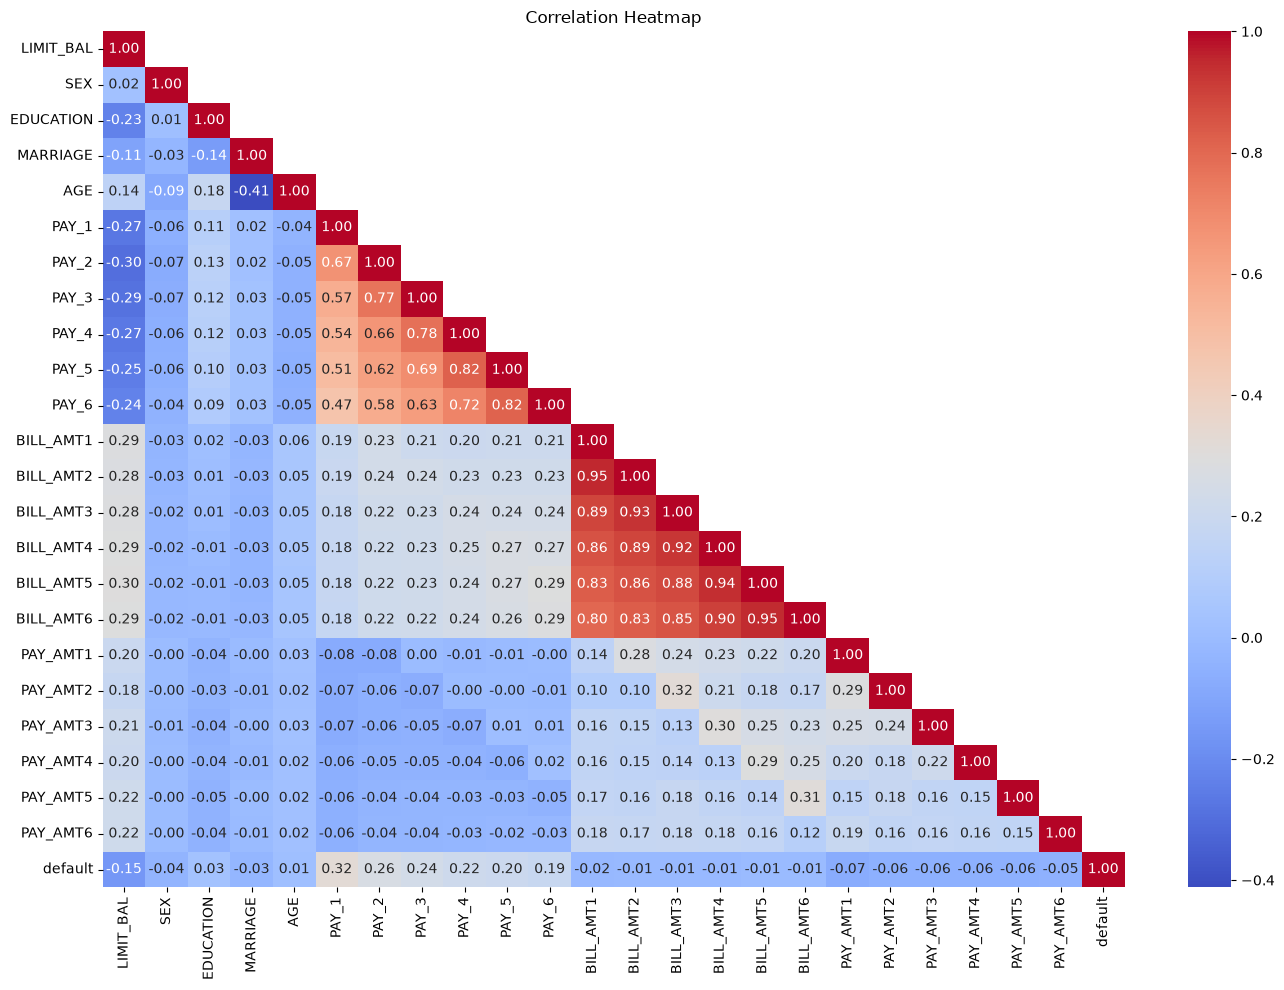

Top Correlations with Default:
PAY_1        0.3248
PAY_2        0.2636
PAY_3        0.2353
PAY_4        0.2166
PAY_5        0.2041
PAY_6        0.1869
LIMIT_BAL   -0.1535
PAY_AMT1    -0.0729
PAY_AMT2    -0.0586
PAY_AMT4    -0.0568
PAY_AMT3    -0.0563
PAY_AMT5    -0.0551
PAY_AMT6    -0.0532
SEX         -0.0400
EDUCATION    0.0338
MARRIAGE    -0.0276
BILL_AMT1   -0.0196
BILL_AMT2   -0.0142
BILL_AMT3   -0.0141
AGE          0.0139
BILL_AMT4   -0.0102
BILL_AMT5   -0.0068
BILL_AMT6   -0.0054
Name: default, dtype: float64


In [32]:
# Calculate correlation matrix
corr_matrix = df_clean.corr()

# Plot heatmap
plt.figure(figsize=(14, 10))

sns.heatmap(
    corr_matrix,
    cmap="coolwarm",
    annot=True,
    fmt=".2f",
    mask=np.triu(np.ones_like(corr_matrix, dtype=bool), k=1)
)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

# Display top correlations with default
print("Top Correlations with Default:")
print(
    corr_matrix["default"]
    .drop("default")
    .sort_values(key=abs, ascending=False)
    .round(4)
)

## 8. Key EDA Findings (Carried Forward to Feature Engineering & Testing)

1. **Class Imbalance (`22.12%` Default):** Out of `30,000` customers, `6,636` defaulted and `23,364` did not. Downstream modeling requires stratified splitting (`stratify=y`), PR-AUC as the primary optimization metric, class-weighted estimators, and F1-optimal probability threshold tuning on out-of-fold validation predictions.
2. **Repayment History Dominates Risk (`PAY_1..PAY_6`):** Customers with revolving credit (`PAY_1 = 0`) default at only `12.88%`, whereas a single month's payment delay in September (`PAY_1 = 1`) jumps the default rate to **`33.95%`**, and a 2+ month delay (`PAY_1 >= 2`) surges default risk to **`67.9%–76.0%`**. Summary delinquency features (`MAX_DELAY`, `AVG_DELAY`, `NUM_DELAYED_MONTHS`, `EVER_SEVERE_DELAY`, `DELAY_TREND`) will capture both severity and persistence.
3. **Credit Limit (`LIMIT_BAL`) & Utilization Signal:** Default rates decline monotonically from **`31.8%`** in the lowest credit-limit decile (`10k–30k NT$`) down to **`11.3%`** in the highest decile (`>360k NT$`). Combining `BILL_AMT` with `LIMIT_BAL` into utilization ratios (`CREDIT_UTIL_1..6`, `AVG_UTIL`, `MAX_UTIL`, `OVER_LIMIT_MONTHS`) directly measures credit exhaustion.
4. **Severe Multicollinearity in `BILL_AMT1..6`:** Adjacent monthly bill statements exhibit $r = 0.88 - 0.95$. Engineering summary bill trends (`AVG_BILL`, `MAX_BILL`, `BILL_TREND`, `UNPAID_BALANCE`) and payment-to-previous-bill coverage ratios (`PAY_RATIO_k = PAY_AMT_k / BILL_AMT_{k+1}`) extracts orthogonal behavioral signal and aids regularized linear models.
5. **Heavy Right Skewness in Monetary Amounts:** Credit limits, bills, and payments span orders of magnitude; applying `log1p` transforms stabilizes variance for `LogisticRegression`.
6. **Undocumented Category Codes Resolved:** Merging `EDUCATION in {0, 5, 6} -> 4` (468 total in `Others`) and `MARRIAGE == 0 -> 3` (377 total in `Others`) eliminates sparse noise bins before Chi-Square testing and one-hot encoding.

In [34]:
# Save cleaned dataset
clean_path = "data/processed/clean.csv"

df_clean.to_csv(clean_path, index=False)

print("Dataset saved successfully!")
print("Total rows:", df_clean.shape[0])
print("Total columns:", df_clean.shape[1])

Dataset saved successfully!
Total rows: 30000
Total columns: 24
